In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [3]:
Gam_quark = np.linspace(2.5,3.5,100)
n_quark = np.linspace(0.5344,1,20)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,20)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

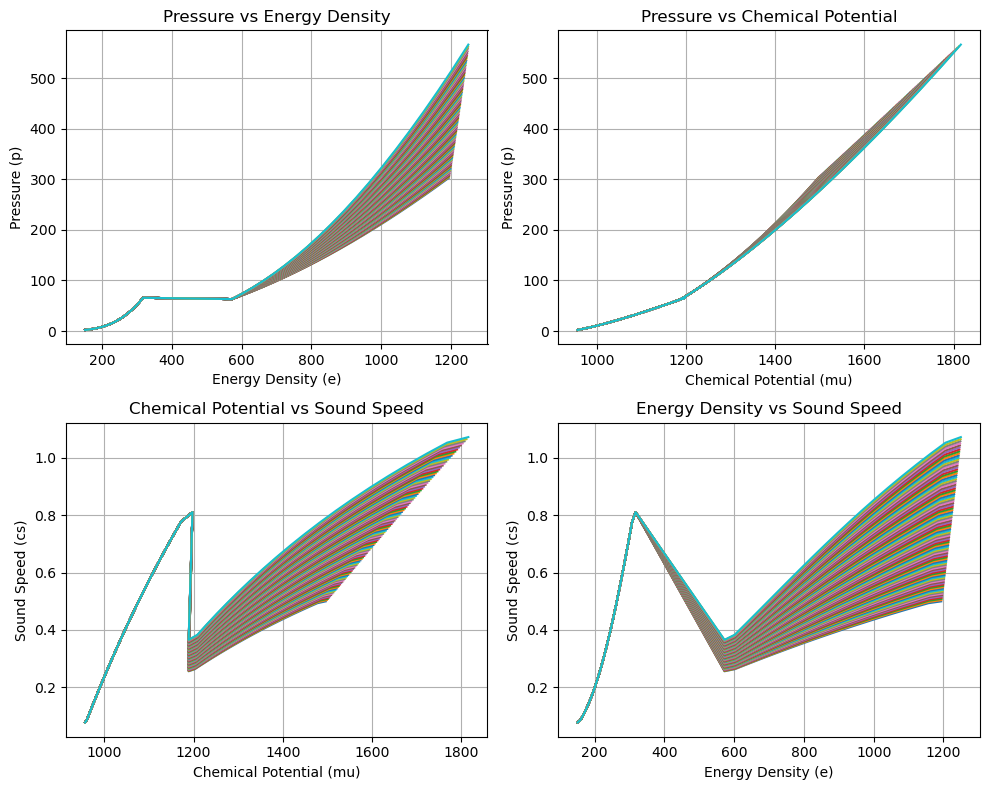

In [4]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
# Initialize empty lists to store concatenated data
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = [], [], [], [], [], []

# Loop through Gam_quark to plot curves for each value of g_quark
for g_quark in Gam_quark:
    K_quark = p / (n_quark[0] ** g_quark)
    m0_quark = (e - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

    # Hadronic EOS
    p_had = P_from_nb(n_had, K_had, Gam_had)
    mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
    e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
    cs_had = np.gradient(p_had, e_had)

    # Quark EOS
    p_quark = P_from_nb(n_quark, K_quark, g_quark)
    mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
    e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
    cs_quark = np.gradient(p_quark, e_quark)

    # Concatenate hadronic and quark data
    e_combined = np.concatenate((e_had, e_quark))
    p_combined = np.concatenate((p_had, p_quark))
    mu_combined = np.concatenate((mu_had, mu_quark))
    cs_combined = np.concatenate((cs_had, cs_quark))

    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit.append(p_quark[0])
    mu_crit.append(mu_quark[0])


# After the loop, plot concatenated data
for i in range(len(Gam_quark)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()



In [5]:
n_had_final = np.linspace(0.3,0.35,20)
n_quark_final = np.linspace(0.5,0.55,20)

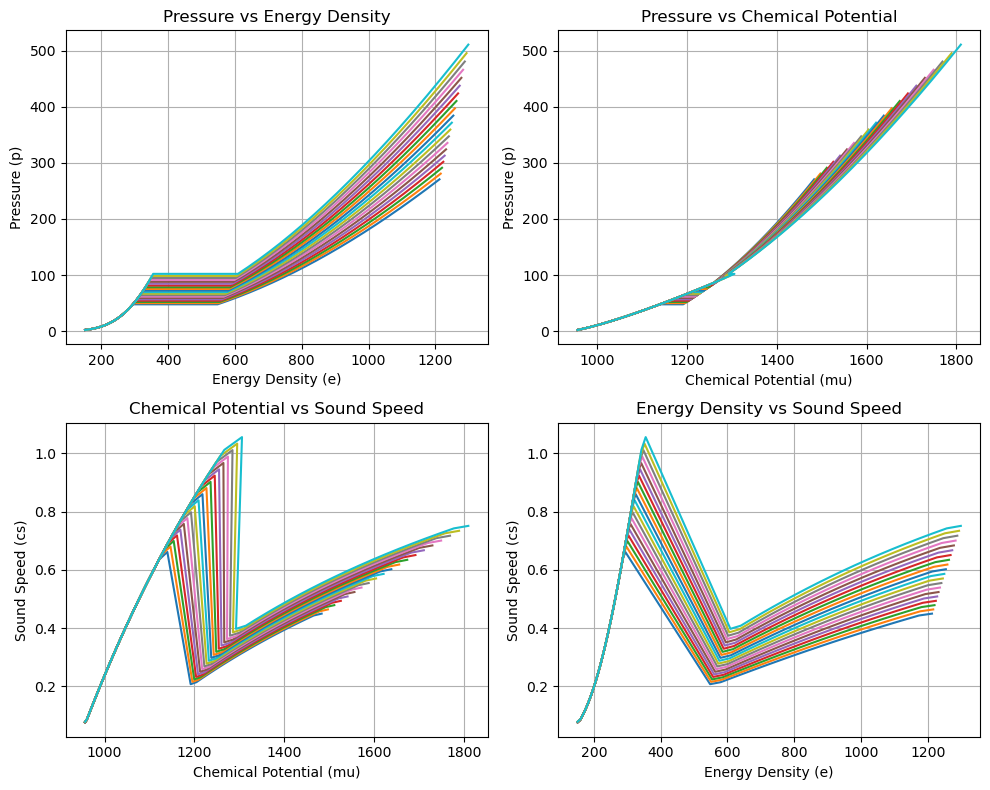

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Initialize empty lists to store concatenated data
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = [], [], [], [], [], []

# Loop through Gam_quark to plot curves for each value of g_quark
for g_quark, nhf, nqf in zip(Gam_quark, n_had_final, n_quark_final):
    n_had = np.linspace(0.16, nhf, 20)
    n_quark = np.linspace(nqf, 1, 20)

    # Hadronic EOS
    p_had = P_from_nb(n_had, K_had, Gam_had)
    mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
    e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
    cs_had = np.gradient(p_had, e_had)

    K_quark = p_had[-1] / (nqf ** g_quark)
    m0_quark = ((e_had[-1]+253.89) - (K_quark * (nqf ** g_quark)) / (g_quark - 1)) / nqf

    # Quark EOS
    p_quark = P_from_nb(n_quark, K_quark, g_quark)
    mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
    e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
    cs_quark = np.gradient(p_quark, e_quark)

    # Concatenate hadronic and quark data
    e_combined = np.concatenate((e_had, e_quark))
    p_combined = np.concatenate((p_had, p_quark))
    mu_combined = np.concatenate((mu_had, mu_quark))
    cs_combined = np.concatenate((cs_had, cs_quark))

    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit.append(p_quark[0])
    mu_crit.append(mu_quark[0])

# After the loop, plot concatenated data
for i in range(len(p_total)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i], label=f"g_quark = {Gam_quark[i]}")

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i], label=f"g_quark = {Gam_quark[i]}")

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i], label=f"g_quark = {Gam_quark[i]}")

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i], label=f"g_quark = {Gam_quark[i]}")

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


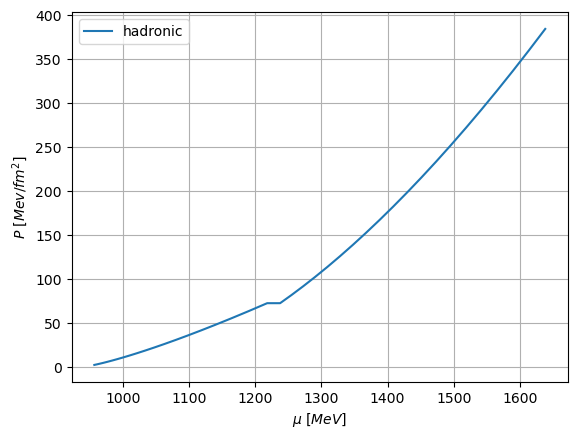

In [7]:
plt.plot(mu_total[10], p_total[10], label = "hadronic")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [8]:
len(p_total[0])

40

In [9]:
P_crit_1 = p*(1+0.01)
P_crit_2 = p*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)


In [15]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[0], P  # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)

    # Find the index of the minimum distance across all runs
    index = min_distances.argmin()

    # Save a specific optimal value to P_all based on index
    P_all.append(P_optimal[index])
    P_all_1.append(P_optimal[0])
    P_max_points.append(min_distance_points[index])
    P_max_points_1.append(min_distance_points[0])


In [16]:
len(Gam_quark)

100

In [17]:
len(P_all_1)

20

In [18]:
len(mu_total)

20

In [13]:
P_all_1

[77.4168048948949,
 77.10503051051052,
 76.77491645645645,
 76.42646273273273,
 76.07800900900901,
 75.71121561561561,
 75.34442222222222,
 74.97762882882883,
 74.59249576576576,
 74.20736270270271,
 73.82222963963964,
 73.45543624624625,
 73.07030318318319,
 72.68517012012012,
 72.31837672672673,
 71.95158333333333,
 71.58478993993994,
 71.23633621621622,
 70.90622216216217,
 70.57610810810812]

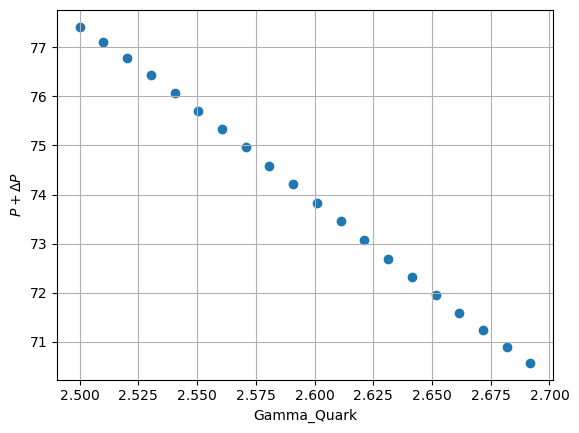

In [19]:
plt.scatter(Gam_quark[:20],P_all_1);
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'$P + \Delta P $');
plt.show();

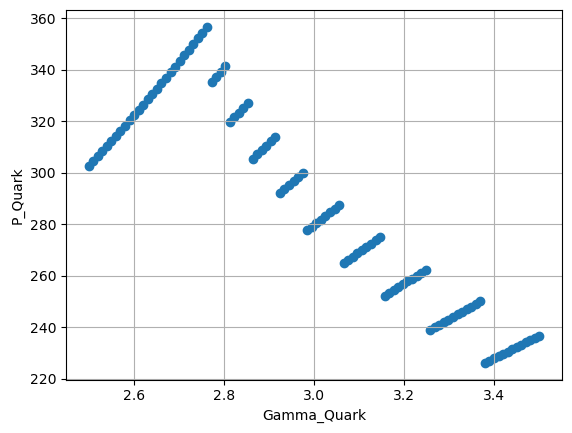

In [11]:
plt.scatter(Gam_quark,[y for x,y in P_max_points_1]);
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'P_Quark');
plt.show();